# import the coeff

In [1]:
import drms
client = drms.Client()

# Ver estructura de la serie
si = client.info('hmi.coefficients')
print(si.primekeys)   # te dice cuáles son las claves primarias reales
print(si.keywords.index.tolist())

query = client.query('hmi.coefficients[2017.08.03_TAI/8d]',key=si.keywords.index.tolist())
query

['T_REC']
['T_REC', 'T_START', 'T_STOP', 'DATAUSED', 'CAL_FSN', 'DATE', 'NDATA', 'COEFF0', 'COEFF1', 'COEFF2', 'COEFF3']


,T_REC,T_START,T_STOP,DATAUSED,CAL_FSN,DATE,NDATA,COEFF0,COEFF1,COEFF2,COEFF3
0,2017.08.03_06:45:00_TAI,2017.08.02_18:45:00_TAI,2017.08.03_18:45:00_TAI,hmi.V_45s_nrt[2017.08.02_18:45:00_TAI-2017.08....,121048472,2017-08-06T16:45:34Z,1881,188.0067,0.006999,-0.000007,-8.414051e-10
1,2017.08.03_18:45:00_TAI,2017.08.03_06:45:00_TAI,2017.08.04_06:45:00_TAI,hmi.V_45s_nrt[2017.08.03_06:45:00_TAI-2017.08....,121048472,2017-08-07T16:50:48Z,1887,187.5741,0.006670,-0.000007,-8.199870e-10
2,2017.08.04_06:45:00_TAI,2017.08.03_18:45:00_TAI,2017.08.04_18:45:00_TAI,hmi.V_45s_nrt[2017.08.03_18:45:00_TAI-2017.08....,121048472,2017-08-07T16:51:18Z,1921,187.2737,0.006637,-0.000007,-8.109732e-10
3,2017.08.04_18:45:00_TAI,2017.08.04_06:45:00_TAI,2017.08.05_06:45:00_TAI,hmi.V_45s_nrt[2017.08.04_06:45:00_TAI-2017.08....,121048472,2017-08-08T16:54:59Z,1921,187.5247,0.006753,-0.000007,-8.256654e-10
4,2017.08.05_06:45:00_TAI,2017.08.04_18:45:00_TAI,2017.08.05_18:45:00_TAI,hmi.V_45s_nrt[2017.08.04_18:45:00_TAI-2017.08....,121048472,2017-08-08T16:55:28Z,1921,187.4194,0.006948,-0.000007,-8.255739e-10
5,2017.08.05_18:45:00_TAI,2017.08.05_06:45:00_TAI,2017.08.06_06:45:00_TAI,hmi.V_45s_nrt[2017.08.05_06:45:00_TAI-2017.08....,121048472,2017-08-09T16:59:22Z,1920,187.1973,0.006837,-0.000007,-8.221256e-10
6,2017.08.06_06:45:00_TAI,2017.08.05_18:45:00_TAI,2017.08.06_18:45:00_TAI,hmi.V_45s_nrt[2017.08.05_18:45:00_TAI-2017.08....,121048472,2017-08-09T16:59:51Z,1919,187.4114,0.006596,-0.000007,-8.218669e-10
7,2017.08.06_18:45:00_TAI,2017.08.06_06:45:00_TAI,2017.08.07_06:45:00_TAI,hmi.V_45s_nrt[2017.08.06_06:45:00_TAI-2017.08....,121048472,2017-08-10T17:02:21Z,1920,188.3779,0.007331,-0.000007,-8.708458e-10
8,2017.08.07_06:45:00_TAI,2017.08.06_18:45:00_TAI,2017.08.07_18:45:00_TAI,hmi.V_45s_nrt[2017.08.06_18:45:00_TAI-2017.08....,121048472,2017-08-10T17:02:31Z,1921,189.6946,0.006326,-0.000007,-8.038637e-10
9,2017.08.07_18:45:00_TAI,2017.08.07_06:45:00_TAI,2017.08.08_06:45:00_TAI,hmi.V_45s_nrt[2017.08.07_06:45:00_TAI-2017.08....,121048472,2017-08-11T17:06:58Z,1921,190.8341,0.007165,-0.000006,-8.414437e-10


In [2]:
import numpy as np
coeffs = query.iloc[0][['COEFF0','COEFF1','COEFF2','COEFF3']].values

def f(v,coeffs):
    return coeffs[0] + (v)*coeffs[1] + (v**2)*coeffs[2] + (v**3)*coeffs[3]

def f_inverse(v,coeffs):
    meta_coeffs = coeffs.copy()
    meta_coeffs[0] -= v
    solutions = np.roots(meta_coeffs[::-1])
    return [root.real for root in solutions if root.imag == 0.0][0]



# simulation

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# --- constants (from the Desmos graph, g dropped / set to 1) ---
w_sdo = 2 * np.pi / (1436 * 60)                    # SDO orbital angular rate [rad/s]
R_sdo = 6571 * 1000 + 35756 * 1000                 # SDO orbital radius [m]
R_sun = 695508 * 1000                              # solar radius [m]
d = 1.495979e11                                    # Earth-Sun distance [m]
T_hours = 324                                      # simulated duration [hours]


def w_sun(phi_rad):
    """Differential rotation rate at latitude phi, converted deg/day -> rad/s."""
    deg_per_day = 14.713 - 2.396 * np.sin(phi_rad) ** 2 - 1.787 * np.sin(phi_rad) ** 4
    return (np.pi / 180 / 86400) * deg_per_day


def relative_speed(phi_deg, t):
    """|du/dt| at latitude phi_deg (degrees) over time array t (seconds)."""
    phi = np.radians(phi_deg)
    ws = w_sun(phi)
    cphi = np.cos(phi)
    alpha_deg = 26
    cos_alpha = np.cos(np.radians(alpha_deg))
    sin_alpha = np.sin(np.radians(alpha_deg))

    dux_dt = -R_sdo * w_sdo * np.sin(w_sdo * t) * cos_alpha - R_sun * cphi * ws * np.sin(ws * t)
    duy_dt = R_sdo * w_sdo * np.cos(w_sdo * t) + R_sun * cphi * ws * np.cos(ws * t)
    duz_dt = -R_sdo * w_sdo * np.sin(w_sdo * t) * sin_alpha

    return np.sqrt(dux_dt ** 2 + duy_dt ** 2 + duz_dt ** 2)


def plot_relative_velocity():
    t = np.linspace(0, T_hours * 3600, 5000)  # seconds
    t_hours = t / 3600

    phi_values_deg = [0, 15, 30, 45, 60, 75]

    fig, ax = plt.subplots(figsize=(10, 6))
    for phi_deg in phi_values_deg:
        v = relative_speed(phi_deg, t)
        ax.plot(t_hours, v, label=f"phi = {phi_deg} deg")

    ax.set_xlabel("t (hours)")
    ax.set_ylabel("|du/dt|  (m/s)")
    ax.set_title("Relative LOS velocity between SDO and a solar surface point vs time")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()

    out_path = "/home/thomas/Projects/sun_rotacion_sim/relative_velocity_plot.png"
    fig.savefig(out_path, dpi=150)
    print(f"Saved plot to {out_path}")





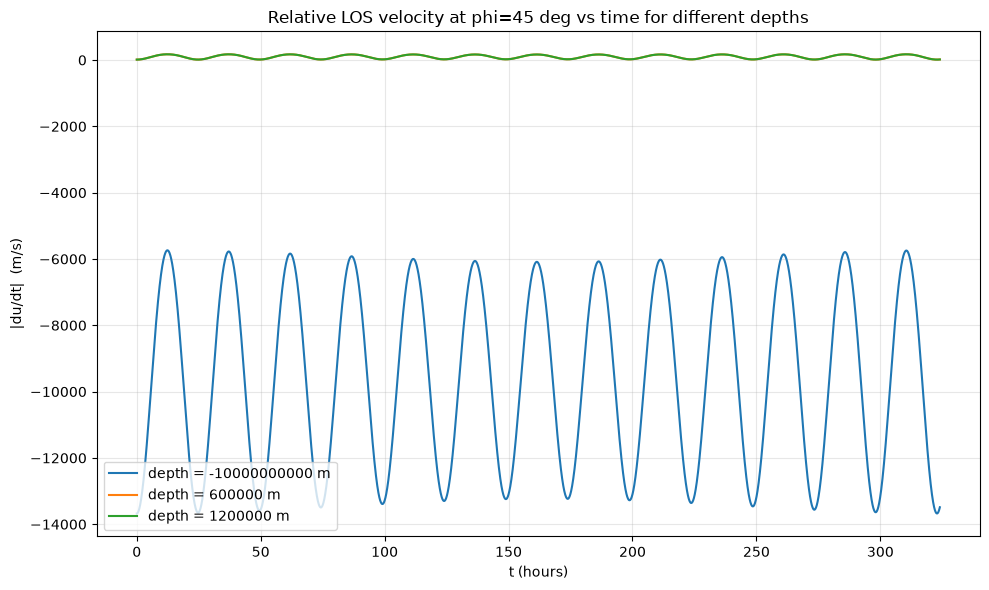

In [13]:
phi = 45
"""Plot relative velocity for a given phi, comparing different depths."""
t = np.linspace(0, T_hours * 3600, 5000)  # seconds
t_hours = t / 3600

depths = [-10000000000, 600*1000,1200*1000]  # depths in meters
fig, ax = plt.subplots(figsize=(10, 6))
for depth in depths:
    global R_sun
    R_sun_original = R_sun
    R_sun -= depth  # adjust Earth-Sun distance for depth
    v = relative_speed(phi, t)
    R_sun = R_sun_original  # reset R_sun
    v_original = relative_speed(phi, t)  # compute original for comparison
    ax.plot(t_hours, f(v), label=f"depth = {depth} m")

ax.set_xlabel("t (hours)")
ax.set_ylabel("|du/dt|  (m/s)")
ax.set_title(f"Relative LOS velocity at phi={phi} deg vs time for different depths")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()


In [5]:
def f(x):
    return 188.0067 + x*0.006999 - 0.000007*(x**2)	- (8.414051e-10)*(x**3)

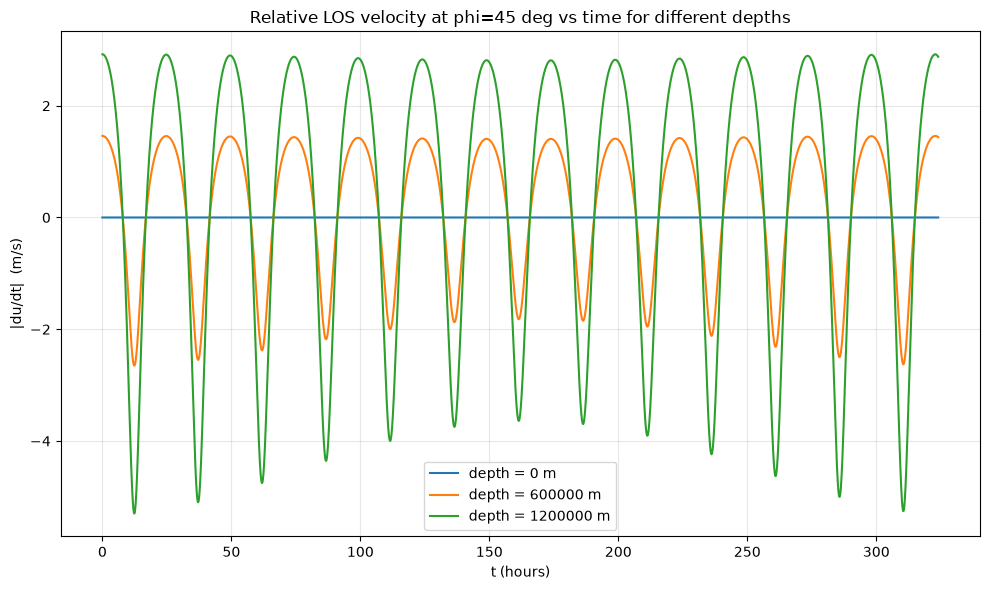

In [6]:
phi = 45
"""Plot relative velocity for a given phi, comparing different depths."""
t = np.linspace(0, T_hours * 3600, 5000)  # seconds
t_hours = t / 3600

depths = [0, 600*1000,1200*1000]  # depths in meters
fig, ax = plt.subplots(figsize=(10, 6))
for depth in depths:
    global R_sun
    R_sun_original = R_sun
    R_sun -= depth  # adjust Earth-Sun distance for depth
    v = relative_speed(phi, t)

    vel_list=np.array([])
    for vel in v:
        vel_list = np.append(vel_list,f_inverse(vel,coeffs))

    R_sun = R_sun_original  # reset R_sun
    v_original = relative_speed(phi, t)  # compute original for comparison

    vel_list_original = np.array([])
    for vel in v_original:
        vel_list_original= np.append(vel_list_original,f_inverse(vel,coeffs))

    ax.plot(t_hours, vel_list-vel_list_original, label=f"depth = {depth} m")

ax.set_xlabel("t (hours)")
ax.set_ylabel("|du/dt|  (m/s)")
ax.set_title(f"Relative LOS velocity at phi={phi} deg vs time for different depths")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
